In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import os

df = pd.read_csv("data/clean/ab_clean.csv")
daily = df.groupby(["date", "group"])["converted"].agg(["sum", "count"]).unstack()
cum = daily.cumsum()

x_t, n_t = cum[("sum", "treatment")], cum[("count", "treatment")]
x_c, n_c = cum[("sum", "control")], cum[("count", "control")]
pool = (x_t + x_c) / (n_t + n_c)
z = (x_t / n_t - x_c / n_c) / np.sqrt(pool * (1 - pool) * (1 / n_t + 1 / n_c))

peek = pd.DataFrame({
    "day": range(1, len(cum) + 1),
    "diff_pp": ((x_t / n_t - x_c / n_c) * 100).round(3),
    "p_value": (2 * (1 - norm.cdf(abs(z)))).round(4)})
peek["would_stop?"] = np.where(peek["p_value"] < 0.05, "STOP - 'winner'", "")
peek

,day,diff_pp,p_value,would_stop?
date,,,,
2017-01-02,1,-0.569,0.5119,
2017-01-03,2,-0.175,0.7074,
2017-01-04,3,-0.320,0.3743,
2017-01-05,4,-0.464,0.1269,
2017-01-06,5,-0.172,0.5204,
2017-01-07,6,-0.229,0.3442,
2017-01-08,7,-0.163,0.4618,
2017-01-09,8,-0.163,0.4309,
2017-01-10,9,0.018,0.9249,


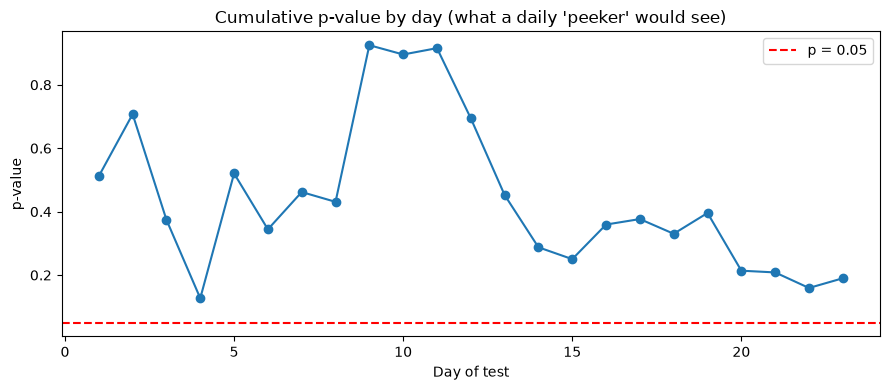

In [2]:
plt.figure(figsize=(9, 4))
plt.plot(peek["day"], peek["p_value"], marker="o")
plt.axhline(0.05, color="red", linestyle="--", label="p = 0.05")
plt.title("Cumulative p-value by day (what a daily 'peeker' would see)")
plt.xlabel("Day of test")
plt.ylabel("p-value")
plt.legend()
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/peeking_real.png", dpi=150)
plt.show()

In [5]:
rng = np.random.default_rng(42)
n_sims, days = 2000, df["date"].nunique()
per_day = int(len(df) / df["date"].nunique() / 2)
base = df.loc[df["group"] == "control", "converted"].mean()

conv_a = rng.binomial(per_day, base, size=(n_sims, days)).cumsum(axis=1)
conv_b = rng.binomial(per_day, base, size=(n_sims, days)).cumsum(axis=1)
n = per_day * np.arange(1, days + 1)

pool = (conv_a + conv_b) / (2 * n)
z = (conv_b / n - conv_a / n) / np.sqrt(pool * (1 - pool) * 2 / n)
pvals = 2 * (1 - norm.cdf(np.abs(z)))

print(f"False 'winners', looking once at the end: {(pvals[:, -1] < 0.05).mean()*100:.1f}%")
print(f"False 'winners', peeking every day:       {(pvals < 0.05).any(axis=1).mean()*100:.1f}%")

False 'winners', looking once at the end: 4.5%
False 'winners', peeking every day:       24.2%


In [6]:
for t in [0.05, 0.01, 0.005, 0.003, 0.001]:
    print(f"Daily threshold p < {t}: false winners = {(pvals < t).any(axis=1).mean()*100:.1f}%")

Daily threshold p < 0.05: false winners = 24.2%
Daily threshold p < 0.01: false winners = 6.4%
Daily threshold p < 0.005: false winners = 3.7%
Daily threshold p < 0.003: false winners = 2.2%
Daily threshold p < 0.001: false winners = 1.4%


In [8]:
peek.reset_index().to_csv("outputs/peeking_daily.csv", index=False)